<a href="https://colab.research.google.com/github/suryansh24-coder/AegisGraph-Sentinel-2.0/blob/master/Logistic_Regression_Code_from_Scratch_Gradient_Descent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from sklearn.datasets import make_classification
import numpy as np
X,y = make_classification(n_samples=100 , n_features=2, n_informative=1 , n_redundant=0 ,
                          n_classes=2 , n_clusters_per_class=1 , random_state=41 , hypercube=False , class_sep=20)

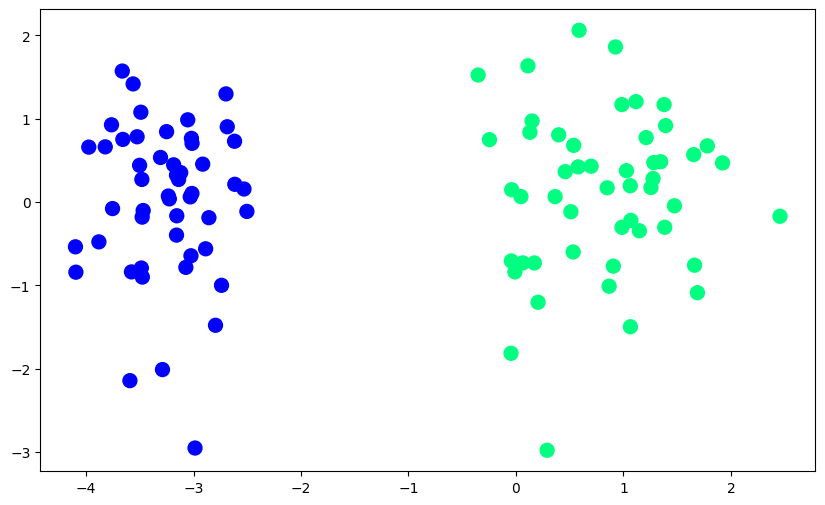

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)

In [4]:
from sklearn.linear_model import LogisticRegression
lor = LogisticRegression(penalty=None, solver='sag')
lor.fit(X, y)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


LogisticRegression(penalty=None, solver='sag')

In [5]:
print(lor.coef_)
print(lor.intercept_)

[[4.78348399 0.20789705]]
[5.75262658]


In [6]:
m1 = -(lor.coef_[0][0]/lor.coef_[0][1])
c1 = -(lor.intercept_[0]/lor.coef_[0][1])

In [8]:
X_input = np.linspace(-3,3,100)
y_input = m1*X_input + c1

In [15]:
def gd(X,y):
  X = np.insert(X,0,1,axis=1)
  weights = np.ones(X.shape[1])
  lr=0.5

  for i in range(2500):
    y_hat = sigmoid(np.dot(X, weights))
    weights = weights + lr*(np.dot((y-y_hat),X)/X.shape[0])

  return weights[1:] , weights[0]

In [16]:
def sigmoid(z):
  return 1/(1+np.exp(-z))

In [17]:
coef_ , intercept_ = gd(X,y)

In [18]:
m = -(coef_[0]/coef_[1])
c = -(intercept_/coef_[1])

In [21]:
x_input1 = np.linspace(-3,3,100)
y_input = m*x_input1 + c

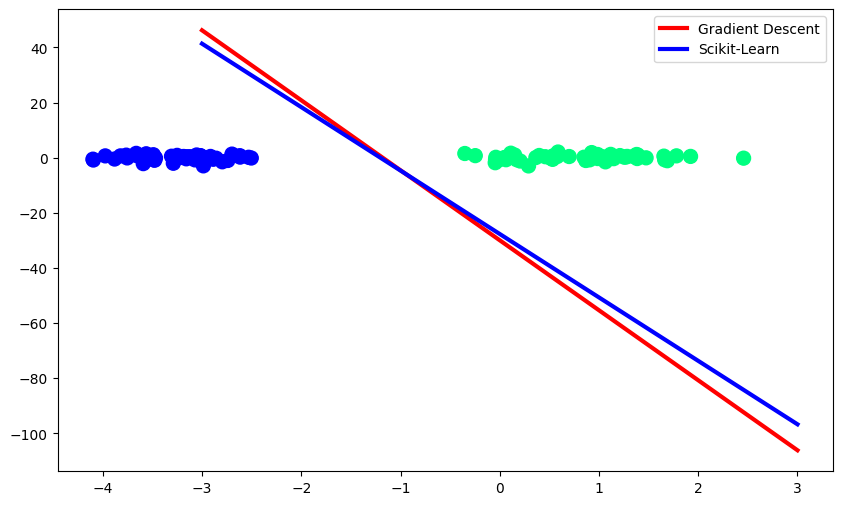

In [23]:
plt.figure(figsize=(10,6))
plt.plot(x_input1, y_input, color='red', linewidth=3, label='Gradient Descent')
plt.plot(X_input, m1*X_input + c1, color='blue', linewidth=3, label='Scikit-Learn')
plt.scatter(X[:,0], X[:,1], c=y, cmap='winter', s=100)
plt.legend()